# Minichallenge 1: Sampling Theory
## Day 1 – Data & Domain

In [17]:
import glob
import numpy as np
from src.knet_io import read_knet


for path in sorted(glob.glob("data/20260926103100/*/ascii/*")):
    acc, fs, hdr = read_knet(path)
    print(hdr["Station Code"], hdr["Max. Acc. (gal)"], path)

FKOH01 0.171 data/20260926103100\kik\ascii\FKOH012609261031.EW1
FKOH01 1.083 data/20260926103100\kik\ascii\FKOH012609261031.EW2
FKOH01 0.138 data/20260926103100\kik\ascii\FKOH012609261031.NS1
FKOH01 1.139 data/20260926103100\kik\ascii\FKOH012609261031.NS2
FKOH01 0.125 data/20260926103100\kik\ascii\FKOH012609261031.UD1
FKOH01 0.393 data/20260926103100\kik\ascii\FKOH012609261031.UD2
FKOH03 0.258 data/20260926103100\kik\ascii\FKOH032609261031.EW1
FKOH03 2.617 data/20260926103100\kik\ascii\FKOH032609261031.EW2
FKOH03 0.324 data/20260926103100\kik\ascii\FKOH032609261031.NS1
FKOH03 2.150 data/20260926103100\kik\ascii\FKOH032609261031.NS2
FKOH03 0.254 data/20260926103100\kik\ascii\FKOH032609261031.UD1
FKOH03 0.845 data/20260926103100\kik\ascii\FKOH032609261031.UD2
FKOH04 0.312 data/20260926103100\kik\ascii\FKOH042609261031.EW1
FKOH04 3.297 data/20260926103100\kik\ascii\FKOH042609261031.EW2
FKOH04 0.226 data/20260926103100\kik\ascii\FKOH042609261031.NS1
FKOH04 2.605 data/20260926103100\kik\asc

| Component | Is suitable for |
|---|---|
| `.NS` / `.EW` (horizontal) | S-Wave, often the strongest vibration. Good for sampling. |
| `.UD` (vertical) | P-Wave, arrives first. Good for runtime-/ crosscorrelation. |

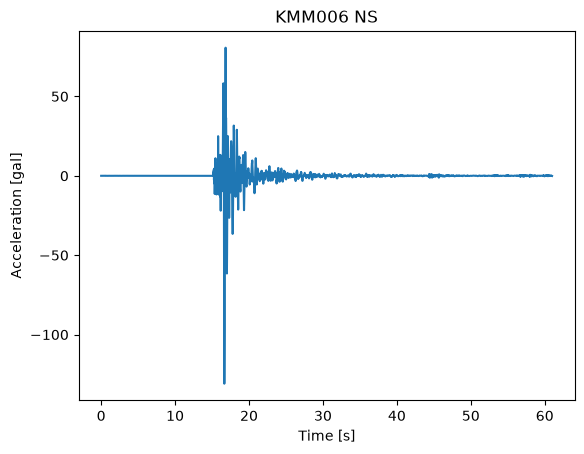

In [18]:
import matplotlib.pyplot as plt

BASE = "data/20260926103100/knet/ascii/KMM0062609261031"
COMPONENTS = ["UD", "NS", "EW"]

records = {}
for comp in COMPONENTS:
    acc_c, fs_c, hdr_c = read_knet(f"{BASE}.{comp}")
    records[comp] = {"acc": acc_c, "t": np.arange(len(acc_c)) / fs_c, "fs": fs_c, "hdr": hdr_c}

r = records["NS"]
plt.plot(r["t"], r["acc"])
plt.xlabel("Time [s]")
plt.ylabel("Acceleration [gal]")
plt.title(f"{r['hdr']['Station Code']} NS")
plt.show()

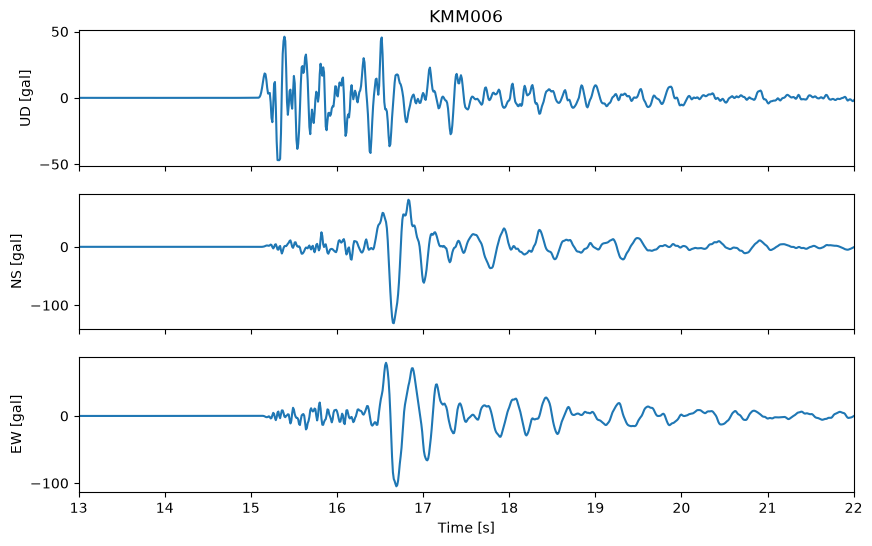

In [19]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 6))
for ax, comp in zip(axes, COMPONENTS):
    ax.plot(records[comp]["t"], records[comp]["acc"])
    ax.set_ylabel(f"{comp} [gal]")
axes[-1].set_xlim(13, 22)   # zoom on P and S onsets
axes[-1].set_xlabel("Time [s]")
axes[0].set_title("KMM006")
plt.show()

Start P-Welle ($tp$): 15.2s <br>
Start S-Wave ($ts$): 16.5s <br>
$tp = d / vp$ and $ts = d / vs$      ($vp$ and $vs$ being the speeds of p/s-waves) <br>
$\Delta t = ts - tp = ( \frac{d}{vs}) - (\frac{d}{vp}) = d (\frac{vp -vs}{vp*vs})$ <br>
$d = \frac{vp*vs}{vp - vs} * \Delta t$ <br>
whereas typical values for $vp$ ~ 6km/s and $vs$ ~ 3.5km/s <br>
we get: <br>
$k = \frac{vp*vs}{vp - vs}= \frac{6 * 3.5}{6 - 3.5} = 8.4$ <br>
Using that formula for $d$: <br>
Intervall P-wave to S-wave $(ts - tp)$ is 1.3 seconds <br>
$distance = 8.4km * (ts -tp) = 11km$

## Use Case: Earthquake Early Warning (EEW) in japan
- Stations like KMM006 measure the p-wave before the destructive s-wave arrives.
- From the first seconds of the p-wave are made measurements of magnitude and expected vibration.
- From this there are given out warnings to citizen.
- Since japan is one of the most earthquake active countries, they have an enormous measurenet

## Problem Statement
The sampling rate decides which frequencies of groundmovements get correctly digitally captured. Is it too low then the fast p-wave samples get folded (Aliasing). They appear as wrong, shallow frequencies and peak values (PGA) are missed. The early warning then estimates a wrong magnitude. Is it too high then we have needless data from multiple stations in realtime, without additional physical information but additional cost for measurement devices.
For this reasons a correct reproduction of frequency and amplitude of the p-wave is important.

## Experimental goal:
I research from which sampling rate the P-/S-wave window of KMM006 is measurably falsified to deduce a minimal but safe sampling rate for EEW-scenarios.

This block investigates the problem using station KMM006 in Kumamoto Prefecture, located almost directly above the hypocenter of the M4.5 event on 2026-09-26.

## Data Source
National Research Institute for Earth Science and Disaster Resilience (NIED): K-NET, KiK-net. doi:10.17598/NIED.0004

### Signal
| Property | Value |
|---|---|
| Physical origin | Ground acceleration caused by the M4.5 earthquake on 2026-09-26, 10:31 (JST), Kumamoto, 10 km depth |
| Station / component | KMM006 (K-NET), UD (vertical) |
| Unit | gal (= cm/s²) |
| Acquisition | Accelerometer, digitized at 100 Hz (raw counts × scale factor) |
| Window | 15–20 s (P-wave onset to early S-wave) |
| Expected frequencies | P-wave ≈ 5–10 Hz, S-wave ≈ 2–4 Hz (estimated visually, to be determined via spectrum on Day 2) |

### Nyquist
Nyquist frequency = highest frequency which by a give sampling rate gets replicated correctly (half the rate). On KNET with a sampling rate of 100Hz you can replicate 50Hz.
Nyquist rate = the sampling rate, which a signal needs at least, double its highest relevant frequency.


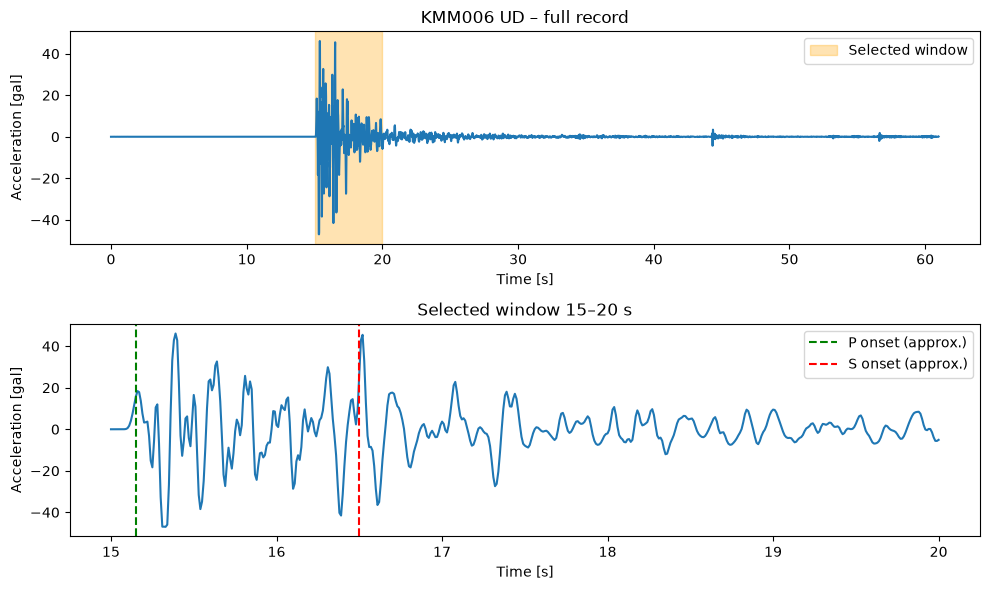

In [20]:
SIGNAL = "UD"
t, acc, fs = records[SIGNAL]["t"], records[SIGNAL]["acc"], records[SIGNAL]["fs"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))
ax1.plot(t, acc)
ax1.axvspan(15, 20, color="orange", alpha=0.3, label="Selected window")
ax1.set(xlabel="Time [s]", ylabel="Acceleration [gal]", title=f"KMM006 {SIGNAL} – full record")
ax1.legend()

mask = (t >= 15) & (t <= 20)
ax2.plot(t[mask], acc[mask])
ax2.axvline(15.15, color="green", ls="--", label="P onset (approx.)")
ax2.axvline(16.5, color="red", ls="--", label="S onset (approx.)")
ax2.set(xlabel="Time [s]", ylabel="Acceleration [gal]", title="Selected window 15–20 s")
ax2.legend()
plt.tight_layout()
plt.show()

## Day 2 – Methodological Design

### Nyquist Shannon Theorem
A continuous-time signal $x(t)$ that is band-limited, i.e. $X(f) = 0$ for $|f| > f_B$, is completely determined by its samples $x(nT_s)$ if the sampling rate satisfies

$$f_s = \frac{1}{T_s} > 2 f_B$$

It can then be reconstructed exactly by sinc interpolation:

$$x(t) = \sum_{n=-\infty}^{\infty} x(nT_s)\,\operatorname{sinc}\!\left(\frac{t - nT_s}{T_s}\right)$$

### Checking the applicability of the theorem
| Assumption | Holds for KMM006 UD? |
|---|---|
| Strictly band-limited signal | **No.** An earthquake is a transient with a sharp P onset, so it is broadband. A finite window is never strictly band-limited either. |
| Infinitely many samples | **No.** The window is only 5 s long (500 samples at 100 Hz). |
| Ideal, instantaneous, noise-free sampling | **Approximately.** The pre-event noise is far below the ~50 gal signal peaks. |
| Ideal sinc reconstruction | **Only approximately.** The infinite sinc sum has to be truncated to the available samples. |

#### Determining the bandwidth $f_B$
Using the energy bandwidth as reference for choosing a bandwidth. $f_B$ is the frequency below which 99% of the spectral energy of the window lies.
$$\int_0^{f_B} |X(f)|^2\,df = 0.99 \int_0^{f_s/2} |X(f)|^2\,df$$

With this choice we can almost capture all of the amplitude and shape of P and S waves, while the remaining 1% above $f_B$ is mostly sensor noise and contributes little to the PGA. This threshold is explicit and reproducable like this.


In [21]:
window = acc[int(15 * fs):int(20 * fs)]
window = window - window.mean()

spectrum = np.abs(np.fft.rfft(window)) ** 2
freqs = np.fft.rfftfreq(len(window), 1 / fs)

cum_energy = np.cumsum(spectrum) / spectrum.sum()
f_B = freqs[np.searchsorted(cum_energy, 0.99)]
print(f"99% energy bandwidth: f_B = {f_B:.1f} Hz")

99% energy bandwidth: f_B = 22.2 Hz


#### Deriving the nyquist frequency and rate
1. Highest relevant frequency in the signal: $f_max = f_B$ = 11.2Hz
2. Nyquist frequency of the signal: $f_N = f_B$ = 11.2Hz
3. Nyquist rate: $f_NR = 2*f_B$ = 22.4Hz
4. Minimum sampling rate: $f_s \gt 2*f_B$ = 22.4Hz

#### Choosing Experiment sampling rates
| Case | Sampling rate | Purpose |
|---|---|---|
| $4 f_B$ | 44.8 Hz | Well above Nyquist, baseline |
| $2 f_B$ (Nyquist rate) | 22.4 Hz | Theoretical limit |
| $1 f_B$ | 11.2 Hz | Below Nyquist, moderate aliasing |
| $0.5 f_B$ | 5.6 Hz | Far below Nyquist, strong aliasing |

## Day 3 – Technical Implementation

#### Parameters

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
from src.knet_io import read_knet

FILE = "data/20260926103100/knet/ascii/KMM0062609261031.UD"
T_START, T_END = 15.0, 20.0   # analysis window [s]
F_B = 11.2                    # 99 % energy bandwidth from Day 2 [Hz]
FS_REF = 1000                 # quasi-continuous reference rate [Hz]

RATES = {
    "4 f_B": 4 * F_B,
    "2 f_B (Nyquist rate)": 2 * F_B,
    "1 f_B": 1 * F_B,
    "0.5 f_B": 0.5 * F_B,
}

for name, fs in RATES.items():
    print(f"{name:22s} fs = {fs:5.1f} Hz   Ts = {1000 / fs:6.1f} ms   fs/2 = {fs / 2:5.1f} Hz")

4 f_B                  fs =  44.8 Hz   Ts =   22.3 ms   fs/2 =  22.4 Hz
2 f_B (Nyquist rate)   fs =  22.4 Hz   Ts =   44.6 ms   fs/2 =  11.2 Hz
1 f_B                  fs =  11.2 Hz   Ts =   89.3 ms   fs/2 =   5.6 Hz
0.5 f_B                fs =   5.6 Hz   Ts =  178.6 ms   fs/2 =   2.8 Hz


#### High Resolution Reference (1kHz)

In [23]:
acc, fs_orig, hdr = read_knet(FILE)

# Upsample the whole record 100 Hz -> 1 kHz (adds no new frequencies)
acc_ref_full = resample_poly(acc, int(FS_REF // fs_orig), 1)
t_ref_full = np.arange(len(acc_ref_full)) / FS_REF

# Cut the window only after upsampling
mask = (t_ref_full >= T_START) & (t_ref_full < T_END)
t_ref, x_ref = t_ref_full[mask], acc_ref_full[mask]

#### Sample Reconstruction

In [24]:
def sample(t_ref, x_ref, fs, t0, t1):
    """Sample the reference at rate fs, starting at t0 (no anti-aliasing filter)."""
    t_s = np.arange(t0, t1, 1 / fs)
    return t_s, np.interp(t_s, t_ref, x_ref)


def sinc_reconstruct(t_s, x_s, fs, t_out):
    """Whittaker-Shannon interpolation: sum of shifted sinc functions."""
    return np.sinc((t_out[:, None] - t_s[None, :]) * fs) @ x_s


samples = {name: sample(t_ref, x_ref, fs, T_START, T_END) for name, fs in RATES.items()}

#### Time Domain Plot

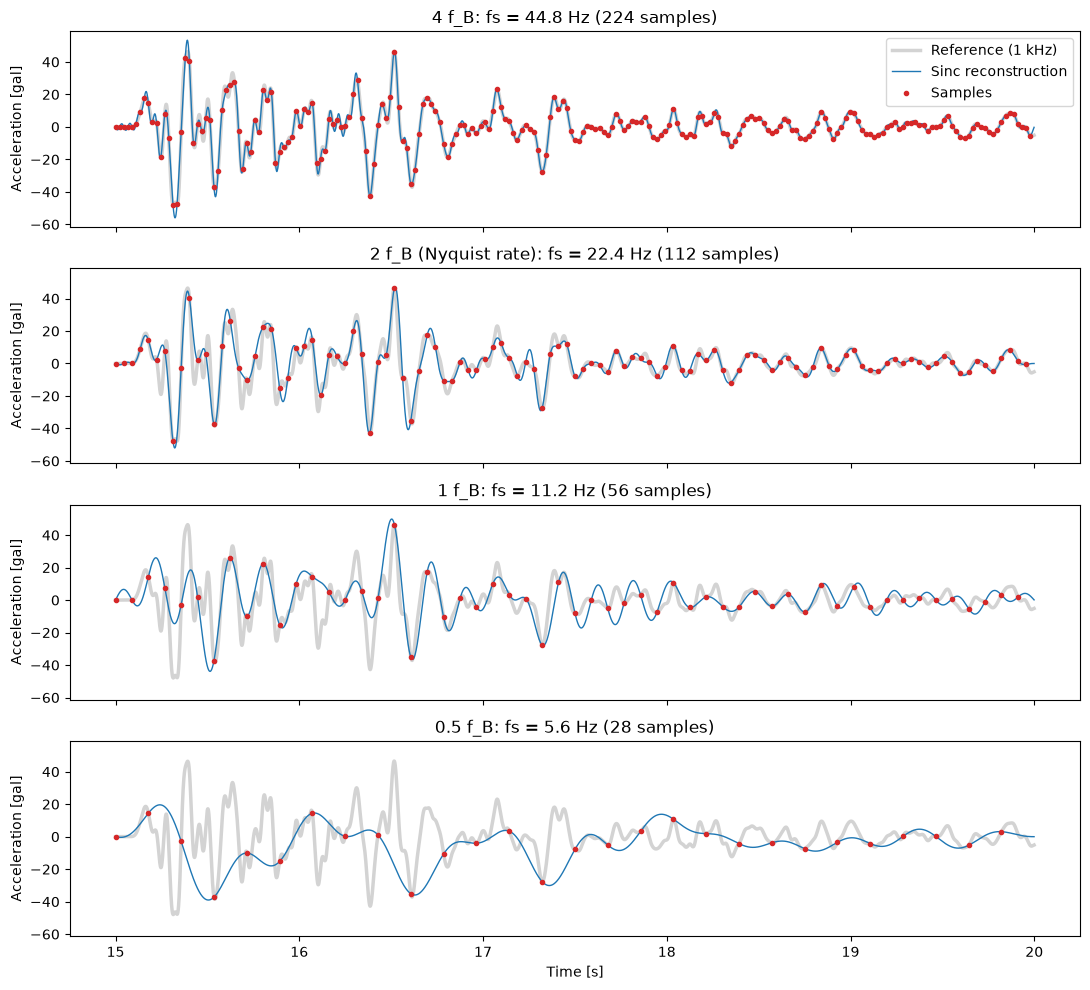

In [25]:
fig, axes = plt.subplots(len(RATES), 1, figsize=(11, 10), sharex=True, sharey=True)

for ax, (name, fs) in zip(axes, RATES.items()):
    t_s, x_s = samples[name]
    x_rec = sinc_reconstruct(t_s, x_s, fs, t_ref)
    ax.plot(t_ref, x_ref, color="lightgray", lw=2.5, label="Reference (1 kHz)")
    ax.plot(t_ref, x_rec, color="tab:blue", lw=1, label="Sinc reconstruction")
    ax.plot(t_s, x_s, "o", color="tab:red", ms=3, label="Samples")
    ax.set_title(f"{name}: fs = {fs:.1f} Hz ({len(t_s)} samples)")
    ax.set_ylabel("Acceleration [gal]")

axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

#### Frequency Domain Plot

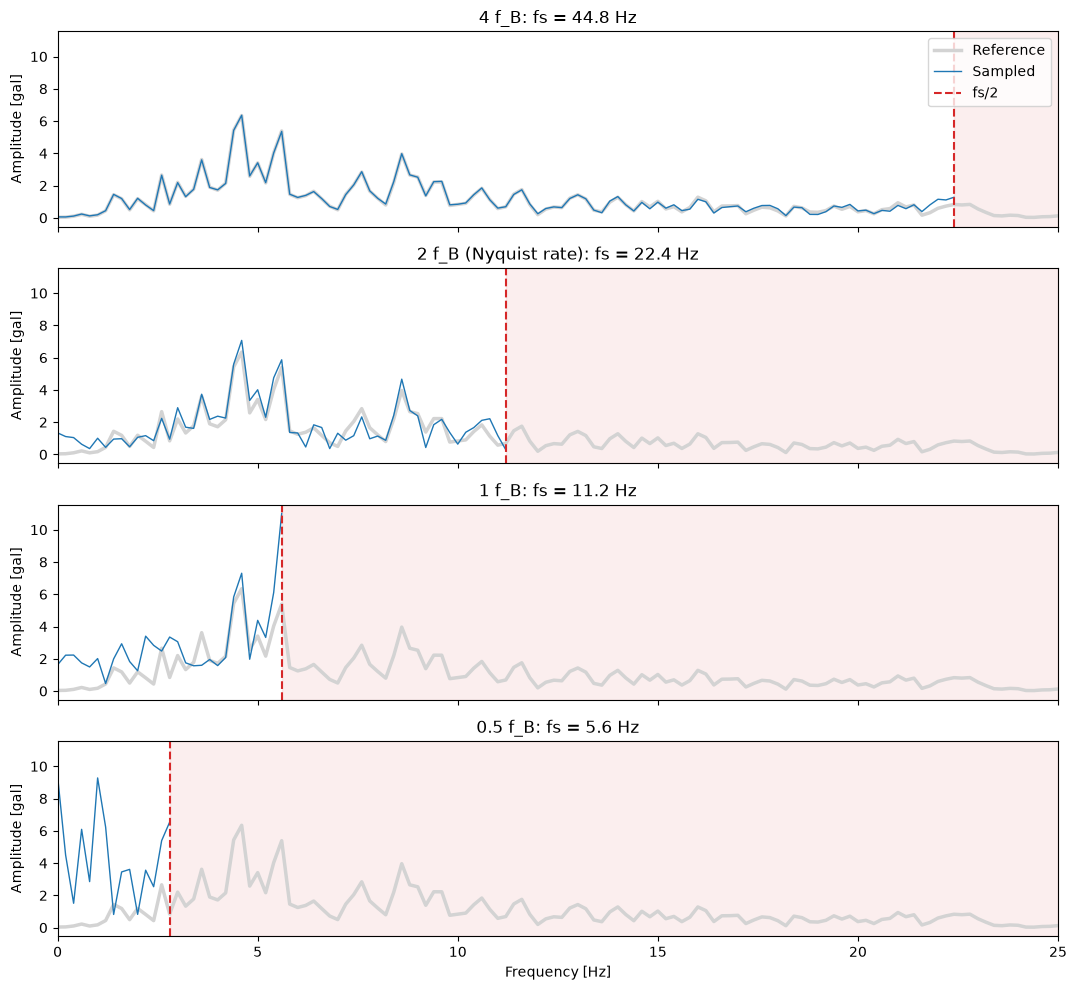

In [26]:
def amplitude_spectrum(x, fs):
    X = np.fft.rfft(x)
    return np.fft.rfftfreq(len(x), 1 / fs), 2 * np.abs(X) / len(x)


f_ref, A_ref = amplitude_spectrum(x_ref, FS_REF)

fig, axes = plt.subplots(len(RATES), 1, figsize=(11, 10), sharex=True, sharey=True)

for ax, (name, fs) in zip(axes, RATES.items()):
    t_s, x_s = samples[name]
    f_s, A_s = amplitude_spectrum(x_s, fs)
    ax.plot(f_ref, A_ref, color="lightgray", lw=2.5, label="Reference")
    ax.plot(f_s, A_s, color="tab:blue", lw=1, label="Sampled")
    ax.axvline(fs / 2, color="tab:red", ls="--", label="fs/2")
    ax.axvspan(fs / 2, 25, color="tab:red", alpha=0.08)
    ax.set_title(f"{name}: fs = {fs:.1f} Hz")
    ax.set_ylabel("Amplitude [gal]")

axes[0].legend(loc="upper right")
axes[-1].set_xlim(0, 25)
axes[-1].set_xlabel("Frequency [Hz]")
plt.tight_layout()
plt.show()

#### Aliasing Demonstration

In [27]:
def alias_frequency(f, fs):
    """Frequency at which a component f appears after sampling at fs."""
    return abs(f - fs * round(f / fs))


for name, fs in RATES.items():
    if fs / 2 >= F_B:
        continue  # only the undersampled cases
    band = (f_ref > fs / 2) & (f_ref < 25)
    f_peak = f_ref[band][np.argmax(A_ref[band])]
    print(f"{name}: strongest component above fs/2 at {f_peak:.2f} Hz "
          f"-> appears at {alias_frequency(f_peak, fs):.2f} Hz")

1 f_B: strongest component above fs/2 at 5.60 Hz -> appears at 5.60 Hz
0.5 f_B: strongest component above fs/2 at 4.60 Hz -> appears at 1.00 Hz


## Day 4 – Evaluation


#### Metric

$$\text{NRMSE} = \frac{\sqrt{\frac{1}{N}\sum (x_{rec} - x_{ref})^2}}{\sqrt{\frac{1}{N}\sum x_{ref}^2}} \cdot 100\,\%$$

NRMSE essentially measures the accuracy of predicted values to the observed values, as such it captures the faithfullness of the waveform in the time interval, hence amplitude and shape. Aliasing falsifies exactly those aspects, wrong swings and missed peaks.
Through normalization we are able to make the measurement regardless the strength of the quake and it is comparable to other stations.
$NRMSE^2$ is the energy proportion of the mistake. This matches our preposition of my 99%-energy-bandwidth and makes the result expectable.
For answering our Use Case our goal is to have an accurate measurement of the P-wave for early warnings.

In [28]:
import pandas as pd

def nrmse(x_rec, x_ref):
    """Normalized root-mean-square error in percent."""
    return 100 * np.sqrt(np.mean((x_rec - x_ref) ** 2)) / np.sqrt(np.mean(x_ref ** 2))


BASELINE = "4 f_B"
cases = {"Original (100 Hz)": 100.0, **RATES}

rows = []
for name, fs in cases.items():
    t_s, x_s = sample(t_ref, x_ref, fs, T_START, T_END)
    x_rec = sinc_reconstruct(t_s, x_s, fs, t_ref)
    rows.append({
        "Case": name,
        "fs [Hz]": round(fs, 1),
        "fs / f_B": round(fs / F_B, 2),
        "Samples": len(t_s),
        "Data vs. 100 Hz [%]": round(100 * fs / 100.0),
        "NRMSE [%]": round(nrmse(x_rec, x_ref), 2),
    })

results = pd.DataFrame(rows)
base = results.loc[results["Case"] == BASELINE, "NRMSE [%]"].item()
results["Δ vs. baseline [pp]"] = (results["NRMSE [%]"] - base).round(2)
results

,Case,fs [Hz],fs / f_B,Samples,Data vs. 100 Hz [%],NRMSE [%],Δ vs. baseline [pp]
0,Original (100 Hz),100.0,8.93,500,100,1.04,-11.92
1,4 f_B,44.8,4.00,224,45,12.96,0.00
2,2 f_B (Nyquist rate),22.4,2.00,112,22,47.92,34.96
3,1 f_B,11.2,1.00,56,11,89.42,76.46
4,0.5 f_B,5.6,0.50,28,6,144.88,131.92


#### Continous rates with argumentative threshold

Significance threshold. Distortion is considered significant when the NRMSE exceeds 10 %. This value follows from the bandwidth definition: $f_B$ was chosen to contain 99 % of the signal energy, so the accepted residual energy of 1 % corresponds to $\sqrt{0.01} = 10\,\%$ of the RMS amplitude. An NRMSE above 10 % therefore indicates error beyond the budget already accepted by the bandwidth choice, i.e. additional distortion caused by sampling. In the context of the use case, a 10 % amplitude deviation changes the JMA instrumental seismic intensity by about $2\log_{10}(1.1) \approx 0.08$, roughly one sixth of an intensity class width, which keeps intensity-based warnings practically unaffected. As NRMSE measures average waveform error rather than peak error, this is an approximate link. To check robustness, the critical sampling rate is also reported for thresholds of 5 % and 20 %

Distortion is significant (NRMSE > 10 %) for fs <= 45.2 Hz = 4.04 f_B


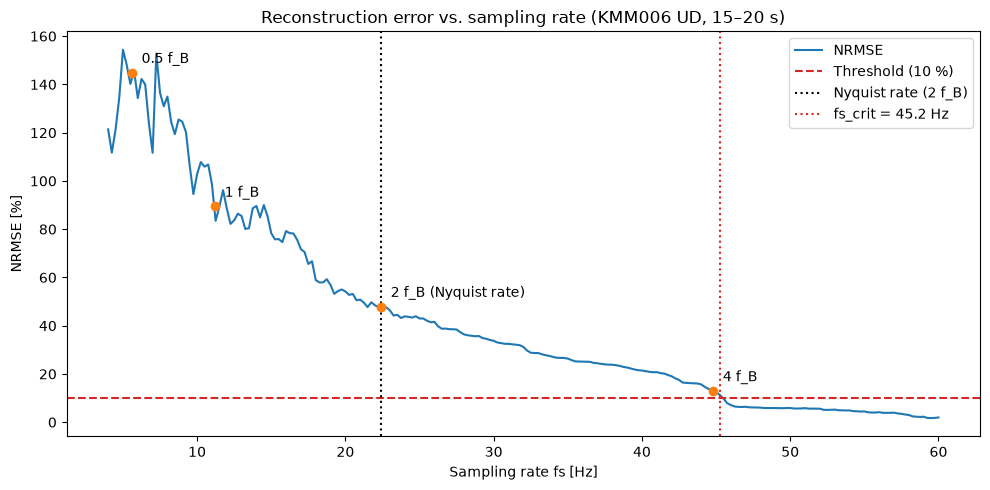

In [29]:
THRESHOLD = 10.0   # NRMSE [%] above which distortion counts as significant

fs_sweep = np.linspace(4, 60, 225)
err = np.array([
    nrmse(sinc_reconstruct(*sample(t_ref, x_ref, fs, T_START, T_END), fs, t_ref), x_ref)
    for fs in fs_sweep
])

exceed = fs_sweep[err > THRESHOLD]
fs_crit = exceed.max() if exceed.size else None
print(f"Distortion is significant (NRMSE > {THRESHOLD:.0f} %) for fs <= {fs_crit:.1f} Hz "
      f"= {fs_crit / F_B:.2f} f_B")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(fs_sweep, err, color="tab:blue", label="NRMSE")
ax.axhline(THRESHOLD, color="tab:red", ls="--", label=f"Threshold ({THRESHOLD:.0f} %)")
ax.axvline(2 * F_B, color="black", ls=":", label="Nyquist rate (2 f_B)")
ax.axvline(fs_crit, color="tab:red", ls=":", label=f"fs_crit = {fs_crit:.1f} Hz")
for name, fs in RATES.items():
    ax.plot(fs, results.loc[results["Case"] == name, "NRMSE [%]"].item(), "o", color="tab:orange")
    ax.annotate(name, (fs, results.loc[results["Case"] == name, "NRMSE [%]"].item()),
                textcoords="offset points", xytext=(7, 7))
ax.set(xlabel="Sampling rate fs [Hz]", ylabel="NRMSE [%]",
       title="Reconstruction error vs. sampling rate (KMM006 UD, 15–20 s)")
ax.legend()
plt.tight_layout()
plt.show()

## Day 5 – Analysis & Communication

#### Observations
The reconstruction error (NRMSE) grows sharply as the sampling rate decreases. At 4 $f_B$ (44.8Hz) the NRMSE is 13% while at the nyquist rate (22.4Hz) the NRMSE is at 48% and below it 90% (11.2Hz) and 145% (5.6Hz) The threshold is exceeded for $f_s$ <= 45.2Hz.

#### Interpretation
Even at the nyquist rate the error is non-zero, because the signal is not band-limited. The 1 % energy above $f_B$ folds back into the band, consistent with the expected ~10%. Below the nyquist rate, the 5-10Hz P-wave components alias to lower frequencies, which distorts the waveform and underestimates peak amplitudes.

#### Discussion
For earthquake early warning, the theoretical minimum of 22.4 Hz is insufficient in practice: real systems need margin for the roll-off of the anti-aliasing filter and for stronger or closer events with higher bandwidth. K-NET’s 100 Hz (≈ 9 $f_B$) provides this margin at moderate data cost. Undersampling would risk underestimated shaking and a distorted P-wave period, which could bias magnitude estimates. Since real recorders filter before digitization, they lose high-frequency content rather than alias it, unlike this experiment. These conclusions are based on one event, station and component and should be verified for larger earthquakes.